**Import Libraries**

In [74]:
# Data Manipulation
import pandas as pd
import numpy as np
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Dataset
from ucimlrepo import fetch_ucirepo
# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
# Model Persistence
import joblib
import os

**Load the Dataset**

In [75]:
# Fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# Validate dataset
if bank_marketing.data is None:
    raise ValueError("Dataset could not be loaded.")

# Extract features and target
X = bank_marketing.data.features
y = bank_marketing.data.targets

# Validate extracted data
if X is None or y is None:
    raise ValueError("Features or targets are unavailable.")

# Combine features and target
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (45211, 17)


In [76]:
# Display the first five records
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


**Exploratory Data Analysis (EDA)**

**Dataset structure and data types**

In [77]:
# Inspect the number of records, columns, data types, and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


**Target variable distribution**

In [78]:
# Count the records in each target class
print("Target Counts:")
print(df["y"].value_counts())

# Calculate the percentage distribution of each target class
print("\nTarget Distribution (%):")
print(df["y"].value_counts(normalize=True) * 100)

Target Counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target Distribution (%):
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


**Missing-value analysis**

In [79]:
# Count missing values in each column
print("Missing Values:")
display(df.isnull().sum().to_frame(name="Missing_Count"))

Missing Values:


,Missing_Count
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


In [80]:
# Calculate missing-value counts and percentages
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (missing_values / len(df)) * 100
})

# Display columns that contain missing values, sorted by percentage
display(
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values(by="Missing_Percentage", ascending=False)
)

,Missing_Count,Missing_Percentage
poutcome,36959,81.747805
contact,13020,28.798301
education,1857,4.107407
job,288,0.637013


**Duplicate-record analysis**

In [81]:
# Check whether the dataset contains duplicate rows
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


**Categorical feature distribution**

In [82]:
# Identify categorical columns and inspect their distinct values
categorical_columns = df.select_dtypes(include=["object", "str"]).columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


job:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64

marital:
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

education:
education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64

default:
default
no     44396
yes      815
Name: count, dtype: int64

housing:
housing
yes    25130
no     20081
Name: count, dtype: int64

loan:
loan
no     37967
yes     7244
Name: count, dtype: int64

contact:
contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

month:
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Nam

**Descriptive statistics**

In [83]:
# Summarize numerical columns using descriptive statistics
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_week,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


**Correlation among numerical features**

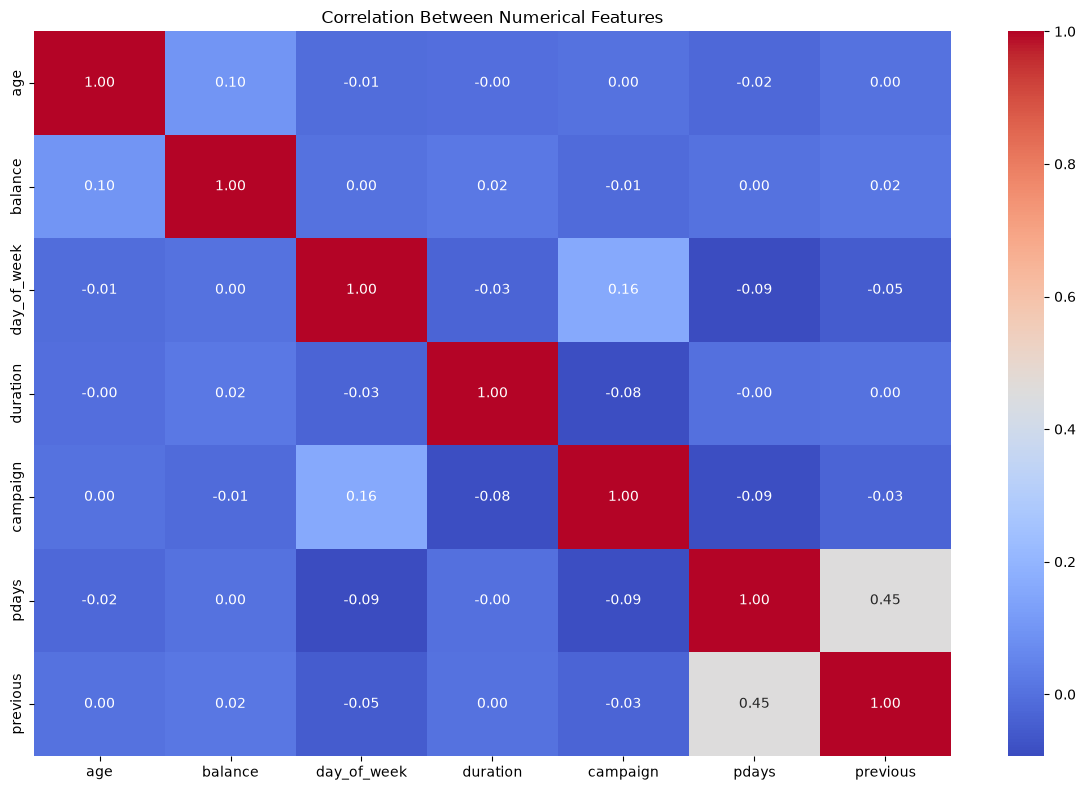

In [84]:
# Select numerical columns for correlation analysis
numerical_df = df.select_dtypes(include=["int64", "float64"])

# Plot the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [85]:
# Inspect missing and available categories in selected categorical columns
columns_to_check = ["job", "education", "contact", "poutcome"]

for col in columns_to_check:
    print(f"\n{col.upper()}")
    print(df[col].value_counts(dropna=False))



JOB
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64

EDUCATION
education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64

CONTACT
contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

POUTCOME
poutcome
NaN        36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64


**Data Preparation and Preprocessing**

In [86]:
# Create a separate copy for modelling
# Exclude duration to avoid using information that is only known after the call
data = df.drop(columns=["duration"]).copy()

print("Original Dataset Shape:", df.shape)
print("Modelling Dataset Shape:", data.shape)

Original Dataset Shape: (45211, 17)
Modelling Dataset Shape: (45211, 16)


In [87]:
# Review missing-value and category counts for selected columns
print(data["contact"].value_counts(dropna=False))
print("\n", data["poutcome"].value_counts(dropna=False))

print("\nMissing values in selected categorical columns:")
display(data[["job", "education", "contact", "poutcome"]].isnull().sum())

contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

 poutcome
NaN        36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

Missing values in selected categorical columns:


job            288
education     1857
contact      13020
poutcome     36959
dtype: int64

In [88]:
# Define numerical input features
numerical_features = [
    "age",
    "balance",
    "day_of_week",
    "campaign",
    "pdays",
    "previous"
]

# Define categorical input features
categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]

# Define the target column
target = "y"

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Total Input Features:", len(numerical_features) + len(categorical_features))

Numerical Features: 6
Categorical Features: 9
Total Input Features: 15


In [89]:
# Separate predictors from the target variable
X = data.drop(columns=[target])

# Encode the target: no = 0, yes = 1
y = data[target].map({"no": 0, "yes": 1})

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nEncoded Target Distribution:")
print(y.value_counts())

X Shape: (45211, 15)
y Shape: (45211,)

Encoded Target Distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [90]:
# Use stratification to preserve the target-class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution (%):")
print(y_test.value_counts(normalize=True) * 100)

Training Data: (36168, 15)
Testing Data: (9043, 15)

Training Target Distribution (%):
y
0    88.301814
1    11.698186
Name: proportion, dtype: float64

Testing Target Distribution (%):
y
0    88.300343
1    11.699657
Name: proportion, dtype: float64


In [91]:
# Numerical preprocessing:
# - Replace missing values with the median.
# - Standardize numerical features.
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [92]:
# Categorical preprocessing for job and education:
# - Replace missing values with the most frequent category.
# - One-hot encode categorical values.
categorical_mode_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Categorical preprocessing for the remaining selected columns:
# - Represent missing values using the category "unknown".
# - One-hot encode categorical values.
categorical_unknown_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

In [93]:
# Apply the appropriate preprocessing pipeline to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat_mode", categorical_mode_pipeline, ["job", "education"]),
        ("cat_unknown", categorical_unknown_pipeline, [
            "marital", "default", "housing", "loan",
            "contact", "month", "poutcome"
        ])
    ],
    remainder="drop"
)

In [94]:
# Fit the preprocessor only on training data to prevent data leakage
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted preprocessor to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (36168, 48)
Processed Testing Shape: (9043, 48)


In [95]:
# Confirm that preprocessing did not leave missing values
print("Training data contains NaN:", np.isnan(X_train_processed).any())
print("Testing data contains NaN:", np.isnan(X_test_processed).any())

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data contains NaN: False
Testing data contains NaN: False

Training target shape: (36168,)
Testing target shape: (9043,)


**Model Building and Training**

In [96]:
# Initialize the five classifiers with their selected baseline settings
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": LinearSVC(
        max_iter=5000,
        random_state=42
    )
}

In [97]:
# Train each classifier on the same preprocessed training data
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)
    trained_models[name] = model

    print(f"{name} trained successfully!\n")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training KNN...
KNN trained successfully!

Training Naive Bayes...
Naive Bayes trained successfully!

Training Support Vector Machine...
Support Vector Machine trained successfully!



**Model Evaluation and Comparison**

In [98]:
# Store evaluation metrics for each trained model
results = []

for name, model in trained_models.items():

    # Generate predicted class labels
    y_pred = model.predict(X_test_processed)

    # Use probabilities for AUC when available.
    # LinearSVC does not provide predict_proba(), so use decision_function().
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)[:, 1]
    else:
        y_score = model.decision_function(X_test_processed)

    # Calculate classification metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    # Append the metrics for the current model
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    print(f"{name} evaluation completed!")

Logistic Regression evaluation completed!
Decision Tree evaluation completed!
KNN evaluation completed!
Naive Bayes evaluation completed!
Support Vector Machine evaluation completed!


In [99]:
# Convert the evaluation results into a DataFrame
results_df = pd.DataFrame(results).set_index("Model")

# Display metrics rounded to four decimal places
display(results_df.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8934,0.7718,0.6655,0.1786,0.2817,0.3073
Decision Tree,0.8335,0.6167,0.3059,0.3336,0.3192,0.2248
KNN,0.8878,0.7045,0.5558,0.2023,0.2966,0.2879
Naive Bayes,0.8444,0.7517,0.3681,0.4603,0.4091,0.3234
Support Vector Machine,0.8932,0.7682,0.6513,0.1871,0.2907,0.3101



Logistic Regression
Confusion Matrix:
[[7890   95]
 [ 869  189]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.67      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043



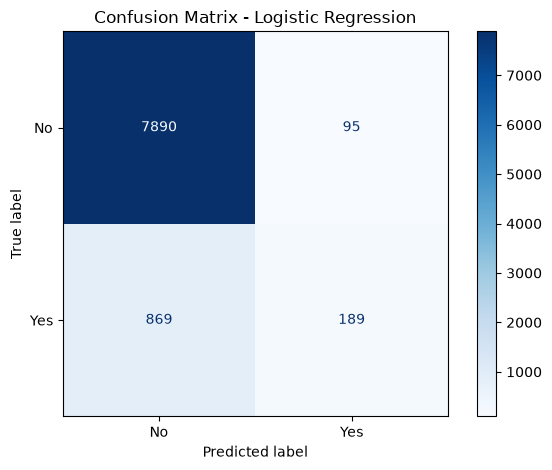


Decision Tree
Confusion Matrix:
[[7184  801]
 [ 705  353]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.91      0.90      0.91      7985
   Subscription       0.31      0.33      0.32      1058

       accuracy                           0.83      9043
      macro avg       0.61      0.62      0.61      9043
   weighted avg       0.84      0.83      0.84      9043



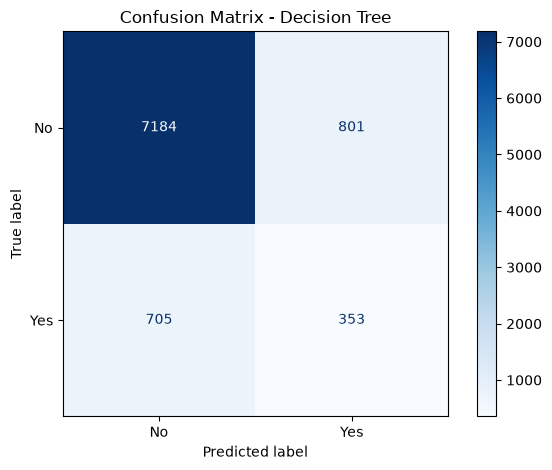


KNN
Confusion Matrix:
[[7814  171]
 [ 844  214]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.98      0.94      7985
   Subscription       0.56      0.20      0.30      1058

       accuracy                           0.89      9043
      macro avg       0.73      0.59      0.62      9043
   weighted avg       0.86      0.89      0.86      9043



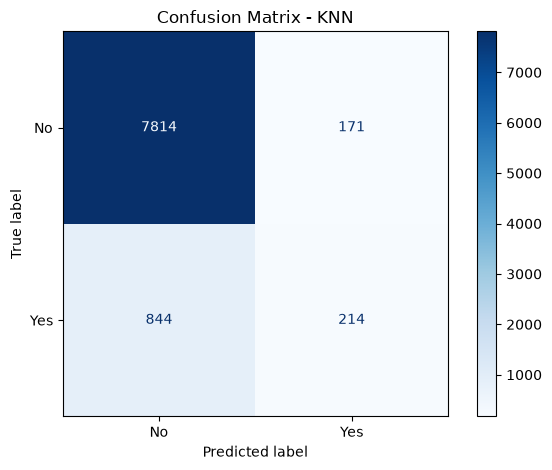


Naive Bayes
Confusion Matrix:
[[7149  836]
 [ 571  487]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.93      0.90      0.91      7985
   Subscription       0.37      0.46      0.41      1058

       accuracy                           0.84      9043
      macro avg       0.65      0.68      0.66      9043
   weighted avg       0.86      0.84      0.85      9043



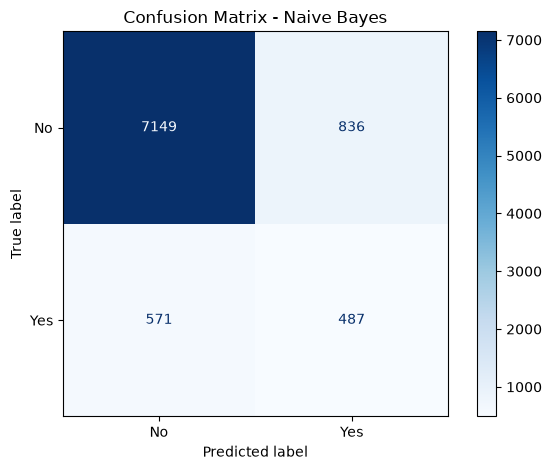


Support Vector Machine
Confusion Matrix:
[[7879  106]
 [ 860  198]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.99      0.94      7985
   Subscription       0.65      0.19      0.29      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.59      0.62      9043
   weighted avg       0.87      0.89      0.87      9043



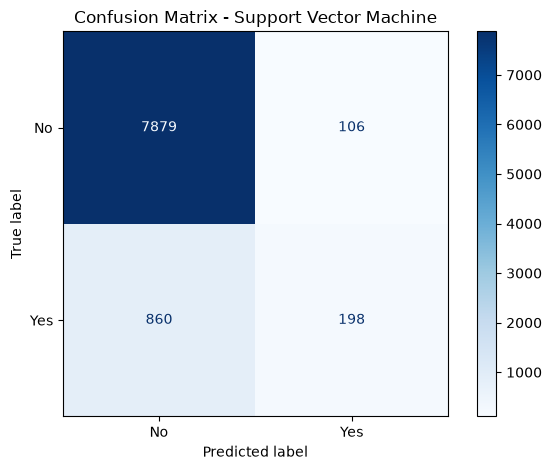

In [100]:
# Generate a confusion matrix and classification report for each model
for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    ))

    # Visualize the confusion matrix
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(cmap="Blues")

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [101]:
# Save the model comparison metrics
results_df.to_csv("model_evaluation_results.csv", index=True)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


**Save Models and Prepare Test Data**

In [102]:
# Create the artifact directory if it does not already exist
os.makedirs("models", exist_ok=True)

In [103]:
# Save the fitted preprocessing pipeline for reuse during inference
joblib.dump(
    preprocessor,
    os.path.join("models", "preprocessor.pkl")
)

print("Preprocessor saved successfully!")

Preprocessor saved successfully!


In [104]:
# Save each trained classifier using a consistent filename
for name, model in trained_models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"
    model_path = os.path.join("models", filename)

    joblib.dump(model, model_path)

    print(f"{filename} saved successfully!")

logistic_regression.pkl saved successfully!
decision_tree.pkl saved successfully!
knn.pkl saved successfully!
naive_bayes.pkl saved successfully!
support_vector_machine.pkl saved successfully!


In [105]:
# Start with the original test features, before preprocessing
test_data = X_test.copy()

# Restore the original target labels for evaluation in the Streamlit app
test_data["y"] = y_test.map({
    0: "no",
    1: "yes"
}).values

# Save the held-out test records for application testing
test_data.to_csv("test_data.csv", index=False)

print("Test data saved successfully!")
print("Test data shape:", test_data.shape)
display(test_data.head())

Test data saved successfully!
Test data shape: (9043, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,NaN,8,may,2,-1,0,NaN,no
7518,44,technician,married,secondary,no,378,yes,no,NaN,30,may,2,-1,0,NaN,no
12007,31,services,married,secondary,no,356,yes,no,NaN,20,jun,5,-1,0,NaN,no
5536,36,blue-collar,married,primary,no,655,yes,no,NaN,23,may,4,-1,0,NaN,no
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,NaN,no
